Convolutional Neural Network (CNN)

In [ ]:
import numpy as np
import matplotlib.pyplot as mat
import pandas as pd
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.linear_model import Perceptron
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.layers import Convolution2D, MaxPooling2D, Flatten
from keras.utils import to_categorical

Mnist dataset is directly available in tensorflow.

In [4]:
from tensorflow.keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# flatten each 28x28 image into a single row of 784 pixel values
X_train_flat = X_train.reshape(X_train.shape[0], -1)   # shape becomes (60000, 784)

# build a DataFrame: one column per pixel, plus the label
df_mnist = pd.DataFrame(X_train_flat, columns=[f"pixel_{i}" for i in range(784)])
df_mnist["label"] = y_train

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [7]:
df_mnist.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783,label
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [8]:
df_mnist.shape

(60000, 785)

In [9]:
df_mnist.describe()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783,label
count,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,...,60000.000000,60000.000000,60000.000000,60000.000000,60000.0000,60000.0,60000.0,60000.0,60000.0,60000.000000
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.088867,0.045633,0.019283,0.015117,0.0020,0.0,0.0,0.0,0.0,4.453933
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.956189,2.839845,1.686770,1.678283,0.3466,0.0,0.0,0.0,0.0,2.889270
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.000000
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,2.000000
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,4.000000
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,7.000000
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,254.000000,253.000000,253.000000,254.000000,62.0000,0.0,0.0,0.0,0.0,9.000000


In [10]:
df_mnist.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, pixel_0 to label
dtypes: uint8(785)
memory usage: 44.9 MB


In [12]:
df_mnist.isnull().sum()

pixel_0      0
pixel_1      0
pixel_2      0
pixel_3      0
pixel_4      0
            ..
pixel_780    0
pixel_781    0
pixel_782    0
pixel_783    0
label        0
Length: 785, dtype: int64

In [11]:
df_mnist.head(4)

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_775,pixel_776,pixel_777,pixel_778,pixel_779,pixel_780,pixel_781,pixel_782,pixel_783,label
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


Data Preprocessing

In [13]:
X= df_mnist.drop("label", axis=1).values
y= df_mnist["label"].values

In [14]:
X= X.astype("float32") / 255.0  # normalize pixel values to [0, 1]

Split into train and test

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Reshape the data/rows into matrix so it becomes image(pixel)

In [18]:
X_train_img= X_train.reshape(-1, 28, 28)  # reshape to (num_samples, 28, 28)
X_test_img= X_test.reshape(-1, 28, 28)

In [19]:
X_train_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

Flattening/ one-hot encoding for "label" i.e y-variable

In [20]:
y_train_cat= to_categorical(y_train, num_classes=10)
y_test_cat= to_categorical(y_test, num_classes=10)

Perceptron model

In [21]:
perceptron= Sequential([Flatten(input_shape=(28, 28)), Dense(10, activation="softmax")])

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [22]:
perceptron.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

In [23]:
perceptron_model= perceptron.fit(X_train_img, y_train_cat, epochs=10, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7991 - loss: 0.8498 - val_accuracy: 0.8661 - val_loss: 0.5415
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.8741 - loss: 0.4862 - val_accuracy: 0.8827 - val_loss: 0.4452
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8862 - loss: 0.4255 - val_accuracy: 0.8913 - val_loss: 0.4051
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8925 - loss: 0.3954 - val_accuracy: 0.8963 - val_loss: 0.3820
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8967 - loss: 0.3763 - val_accuracy: 0.8997 - val_loss: 0.3665
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9000 - loss: 0.3628 - val_accuracy: 0.9026 - val_loss: 0.3553
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9020 - loss: 0.3526 - val_accuracy: 0.9047 - val_loss: 0.3466
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9044 - loss: 0.3

In [24]:
accuracy_perceptron= perceptron.evaluate(X_test_img, y_test_cat, verbose=1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9086 - loss: 0.3293


ANN Model

In [25]:
ann= Sequential([Flatten(input_shape=(28, 28)), Dense(128, activation="leaky_relu"), Dense(64, activation="relu"), Dense(10, activation="softmax")])

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [26]:
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [27]:
ann_model= ann.fit(X_train_img, y_train_cat, epochs=10, batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9184 - loss: 0.2787 - val_accuracy: 0.9543 - val_loss: 0.1559
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9611 - loss: 0.1295 - val_accuracy: 0.9638 - val_loss: 0.1188
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9726 - loss: 0.0908 - val_accuracy: 0.9688 - val_loss: 0.1023
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9802 - loss: 0.0669 - val_accuracy: 0.9697 - val_loss: 0.1001
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9841 - loss: 0.0520 - val_accuracy: 0.9701 - val_loss: 0.1065
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9883 - loss: 0.0406 - val_accuracy: 0.9714 - val_loss: 0.1061
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.9891 - loss: 0.0348 - val_accuracy: 0.9695 - val_loss: 0.1184
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 9ms/step - accuracy: 0.9904 - loss

In [28]:
accuracy_ann= ann.evaluate(X_test_img, y_test_cat, verbose=1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9723 - loss: 0.1219


CNN Model

For CNN, I should provide the colour channel while reshaping
For greyscale= 1
For RGB= 3

In [29]:
X_train_cnn= X_train.reshape(-1, 28, 28, 1)  # reshape to (num_samples, 28, 28, color code)
X_test_cnn= X_test.reshape(-1, 28, 28, 1)

In [31]:
cnn= Sequential([Convolution2D(32, kernel_size= (3,3), activation="relu", input_shape= (28,28,1)), MaxPooling2D(pool_size=(2,2)), Convolution2D(64, kernel_size= (3,3), activation="relu"), MaxPooling2D(pool_size=(2,2)), Flatten(), Dense(128, activation= "leaky_relu"), Dropout(0.5), Dense(10, activation="softmax")])

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [33]:
cnn_model= cnn.fit(X_train_cnn, y_train_cat, epochs=10, batch_size=50, validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 38s 37ms/step - accuracy: 0.9344 - loss: 0.2110 - val_accuracy: 0.9745 - val_loss: 0.0763
Epoch 2/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 45s 47ms/step - accuracy: 0.9780 - loss: 0.0728 - val_accuracy: 0.9849 - val_loss: 0.0477
Epoch 3/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 78s 43ms/step - accuracy: 0.9833 - loss: 0.0525 - val_accuracy: 0.9869 - val_loss: 0.0413
Epoch 4/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 37s 38ms/step - accuracy: 0.9872 - loss: 0.0416 - val_accuracy: 0.9888 - val_loss: 0.0358
Epoch 5/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 35s 37ms/step - accuracy: 0.9894 - loss: 0.0341 - val_accuracy: 0.9884 - val_loss: 0.0382
Epoch 6/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 36s 38ms/step - accuracy: 0.9909 - loss: 0.0291 - val_accuracy: 0.9882 - val_loss: 0.0387
Epoch 7/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - accuracy: 0.9918 - loss: 0.0258 - val_accuracy: 0.9897 - val_loss: 0.0348
Epoch 8/10
960/960 ━━━━━━━━━━━━━━━━━━━━ 40s 37ms/step - accuracy: 0.9925 - loss: 0.0228 - 

In [40]:
accuracy_cnn= cnn.evaluate(X_test_cnn, y_test_cat, verbose=1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9898 - loss: 0.0363


Comparison plots

In [36]:
def plot_training_history(history, title):
    mat.figure(figsize=(12, 4))
    
    # Plot training & validation accuracy values
    mat.subplot(1, 2, 1)
    mat.plot(history.history['accuracy'])
    mat.plot(history.history['val_accuracy'])
    mat.title(f'{title} - Model Accuracy')
    mat.ylabel('Accuracy')
    mat.xlabel('Epoch')
    mat.legend(['Train', 'Validation'], loc='upper left')
    
    # Plot training & validation loss values
    mat.subplot(1, 2, 2)
    mat.plot(history.history['loss'])
    mat.plot(history.history['val_loss'])
    mat.title(f'{title} - Model Loss')
    mat.ylabel('Loss')
    mat.xlabel('Epoch')
    mat.legend(['Train', 'Validation'], loc='upper left')
    
    mat.tight_layout()
    mat.show()

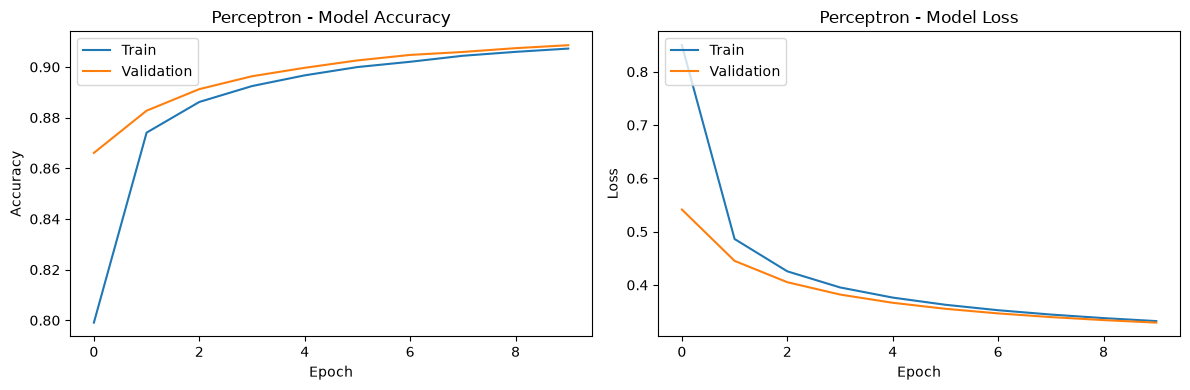

In [37]:
plot_training_history(perceptron_model, "Perceptron")

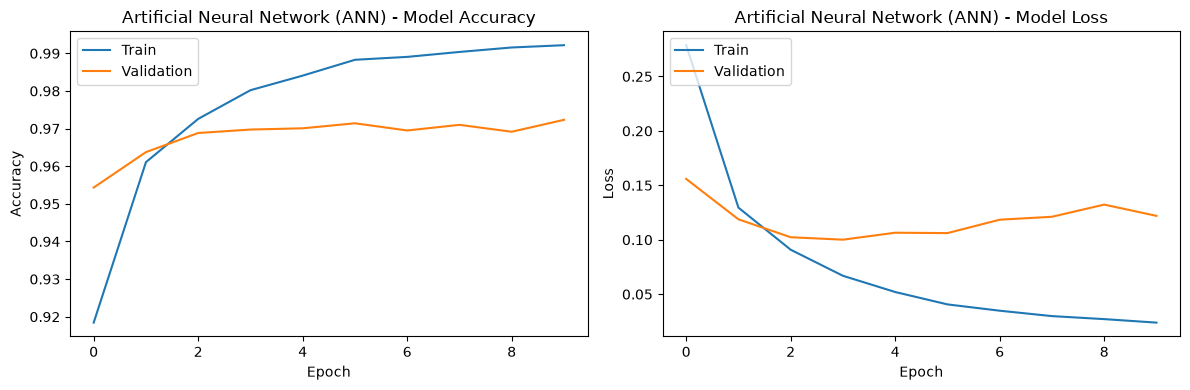

In [38]:
plot_training_history(ann_model, "Artificial Neural Network (ANN)")

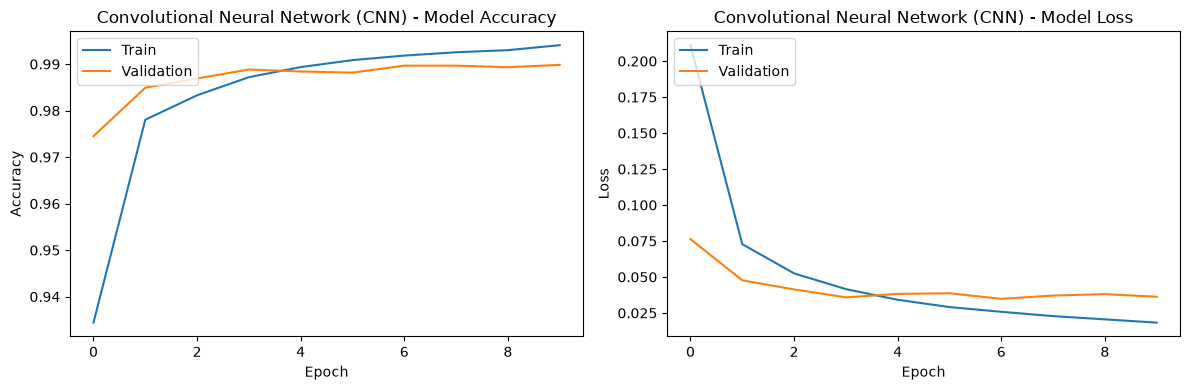

In [39]:
plot_training_history(cnn_model, "Convolutional Neural Network (CNN)")

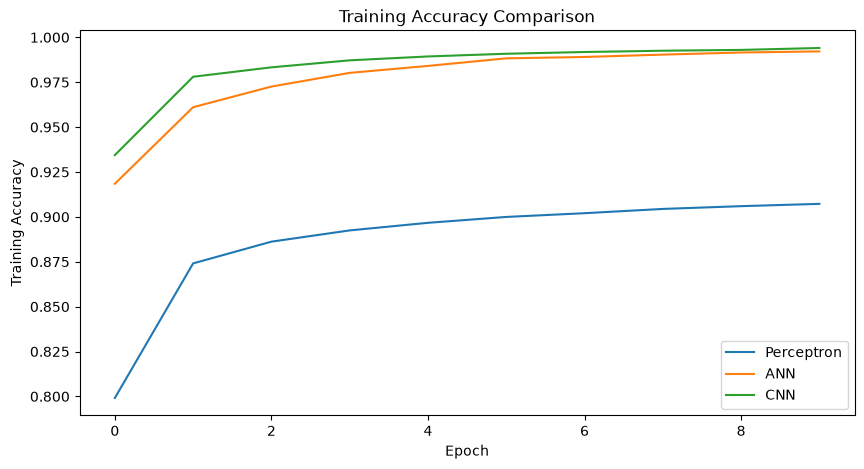

In [42]:
mat.figure(figsize=(10, 5))
mat.plot(perceptron_model.history["accuracy"], label= "Perceptron")
mat.plot(ann_model.history["accuracy"], label= "ANN")
mat.plot(cnn_model.history["accuracy"], label= "CNN")
mat.title("Training Accuracy Comparison")
mat.xlabel("Epoch")
mat.ylabel("Training Accuracy")
mat.legend()
mat.show()

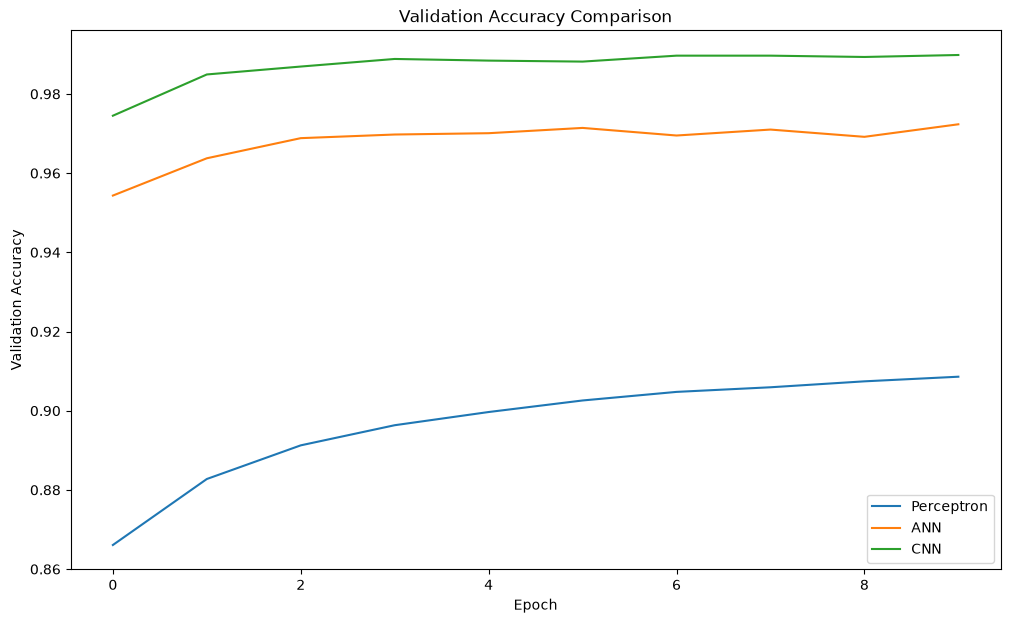

In [41]:
mat.figure(figsize=(12, 7))
mat.plot(perceptron_model.history["val_accuracy"], label= "Perceptron")
mat.plot(ann_model.history["val_accuracy"], label= "ANN")
mat.plot(cnn_model.history["val_accuracy"], label= "CNN")
mat.title("Validation Accuracy Comparison")
mat.xlabel("Epoch")
mat.ylabel("Validation Accuracy")
mat.legend()
mat.show()

Now, I will demonstrate the model side by side for random numbers.

In [53]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=10):
    """
    Display side-by-side predictions from different models for a sample of images.

    Parameters:
    - models: List of trained models (Perceptron, ANN, CNN).
    - model_names: List of model names corresponding to the models.
    - X: Original flattened input data (for Perceptron and ANN).
    - X_cnn: Reshaped input data for CNN.
    - y_true: True labels for the samples.
    - n: Number of samples to display.
    """
    indices = np.random.choice(len(X), n, replace=False)
    
    mat.figure(figsize=(15, 3))
    
    for i, idx in enumerate(indices):
        mat.subplot(2, n, i + 1)
        mat.imshow(X[idx].reshape(28, 28), cmap='gray')
        mat.axis('off')
        mat.title(f'True: {y_true[idx]}')
        pred = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if
        name == "CNN" else X[idx].reshape(1, 28, 28)))
                for model, name in zip(models, model_names)]
        mat.subplot(2, n, n + i + 1)
        mat.axis('off')
        mat.title("\n".join([f"{n}: {p}" for n, p in zip(model_names, pred)]))
    
    mat.tight_layout()
    mat.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 

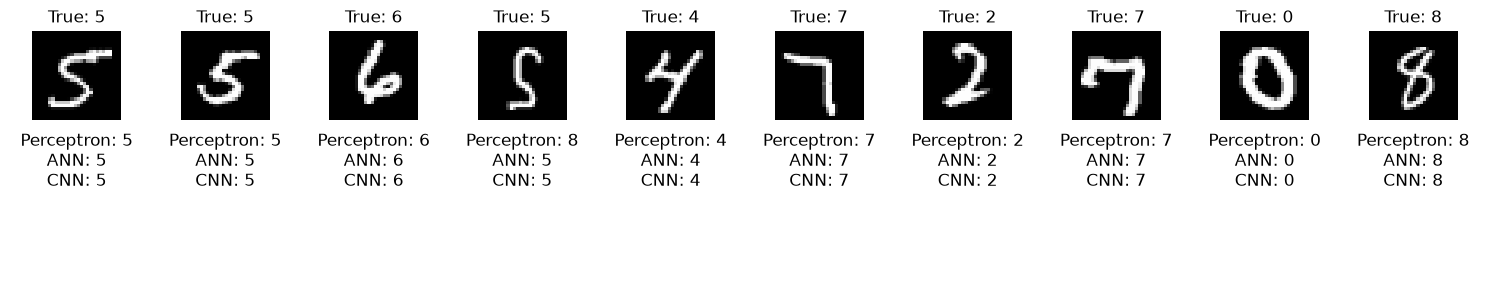

In [54]:
show_side_by_side(models=[perceptron, ann, cnn], 
                   model_names=["Perceptron", "ANN", "CNN"], 
                   X=X_test_img, 
                   X_cnn=X_test_cnn, 
                   y_true=y_test, 
                   n=10)